<a href="https://colab.research.google.com/github/shingihorton/IS4487_Portfolio/blob/main/IS4487_Shingi_assignment_07_data_transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('cleaned_airbnb_data_6.csv')
df.head()

,id,listing_url,source,name,description,picture_url,host_id,host_url,host_profile_id,host_profile_url,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,review_status
0,103760,https://www.airbnb.com/rooms/103760,city scrape,Central Centre 5 min walk to/from Central MTR,"Located right in the heart of Central, this 2 ...",https://a0.muscache.com/pictures/815221/056993...,304876,https://www.airbnb.com/users/show/304876,1462515188084590070,https://www.airbnb.com/users/profile/146251518...,...,4.48,4.63,4.72,4.41,2,2,0,0,1.72,Has reviews
1,163664,https://www.airbnb.com/rooms/163664,city scrape,Soho off Hollywood Road P4,"Fun Fact: Possession St, is where the British ...",https://a0.muscache.com/pictures/15184030/8d06...,304876,https://www.airbnb.com/users/show/304876,1462515188084590070,https://www.airbnb.com/users/profile/146251518...,...,4.44,4.58,4.68,4.31,2,2,0,0,1.24,Has reviews
2,248140,https://www.airbnb.com/rooms/248140,previous scrape,Bright Studio - Soho - Central HK,Our bright studio apartment is perfect for vis...,https://a0.muscache.com/pictures/4e5463bc-38be...,1300549,https://www.airbnb.com/users/show/1300549,1462542170823986906,https://www.airbnb.com/users/profile/146254217...,...,4.94,4.97,4.76,4.79,1,1,0,0,1.34,Has reviews
3,263081,https://www.airbnb.com/rooms/263081,city scrape,"3 睡房, 2500 平方呎 有工人 Family Friendly! 在中環半山 有車","Mid Level on the top of central, Next to the m...",https://a0.muscache.com/pictures/7348025/73278...,1370155,https://www.airbnb.com/users/show/1370155,1462543964897136608,https://www.airbnb.com/users/profile/146254396...,...,NaN,NaN,NaN,NaN,1,0,1,0,NaN,No reviews yet
4,306515,https://www.airbnb.com/rooms/306515,city scrape,"HongKong,Central Bright Double Room",NaN,https://a0.muscache.com/pictures/3335548/00a8d...,1576511,https://www.airbnb.com/users/show/1576511,1462562133322138543,https://www.airbnb.com/users/profile/146256213...,...,4.72,4.84,4.89,4.79,1,1,0,0,0.11,Has reviews


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6734 entries, 0 to 6733
Data columns (total 76 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            6734 non-null   int64  
 1   listing_url                                   6734 non-null   object 
 2   source                                        6734 non-null   object 
 3   name                                          6734 non-null   object 
 4   description                                   6627 non-null   object 
 5   picture_url                                   6733 non-null   object 
 6   host_id                                       6734 non-null   int64  
 7   host_url                                      6734 non-null   object 
 8   host_profile_id                               6734 non-null   int64  
 9   host_profile_url                              6734 non-null   o

In [31]:
df[['amenities', 'room_type']].head()

,amenities,room_type
0,"[""Heating"", ""Cooking basics"", ""Lockbox"", ""Sham...",Entire home/apt
1,"[""Air conditioning"", ""Smoke alarm"", ""Essential...",Entire home/apt
2,"[""Ceiling fan"", ""Kitchen"", ""Cooking basics"", ""...",Entire home/apt
3,"[""Heating"", ""Elevator"", ""Doorman"", ""Free parki...",Private room
4,"[""Elevator"", ""Doorman"", ""Kitchen"", ""TV"", ""Wash...",Entire home/apt


## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

In [2]:
# Quick view of the price column
df['price']
print (df['price'].describe())

count      6734.000000
mean        782.023982
std        2561.350593
min           0.090000
25%         230.222500
50%         438.500000
75%         942.565000
max      171234.000000
Name: price, dtype: float64


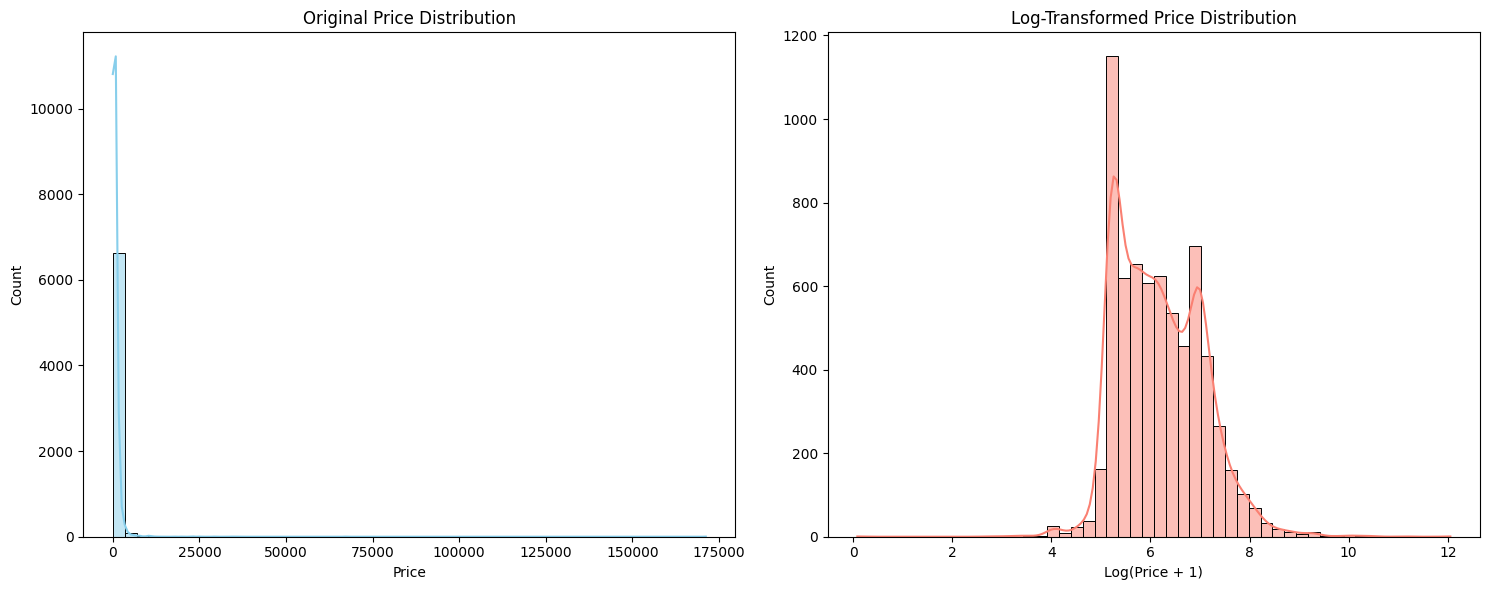

In [3]:
# Calculate the log-transformed price
df['price_log'] = np.log1p(df['price'])

# Create a side-by-side subplot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Original Price Histogram
sns.histplot(df['price'], bins=50, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Original Price Distribution')
axes[0].set_xlabel('Price')
axes[0].set_ylabel('Count')

# 2. Log-Transformed Price Histogram
sns.histplot(df['price_log'], bins=50, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Log-Transformed Price Distribution')
axes[1].set_xlabel('Log(Price + 1)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1.I examined the price column. It has a right skewed distribution.

2.I tried the z-score standardization first and it didn't transform the distribution. It stayed the same. I investigated and it turns out, because of the high max value raises the mean and the smaller values still stay on the left side and the distribution stays right skewed.

3.The second tranformation is usable for a transformation as it is now normalized.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [4]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Initialize the scalers
min_max_scaler = MinMaxScaler()
std_scaler = StandardScaler()

# Min-Max scale
df['total_quote_price_scaled'] = min_max_scaler.fit_transform(df[['price_quote_total_price']])

# Z-score scale
df['bedrooms_standard'] = std_scaler.fit_transform(df[['bedrooms']])

# Display a preview of the actual old and new columns
display(df[['price_quote_total_price', 'total_quote_price_scaled', 'bedrooms', 'bedrooms_standard']].head(10))


,price_quote_total_price,total_quote_price_scaled,bedrooms,bedrooms_standard
0,21258.28,0.039948,2.0,0.461061
1,16441.00,0.030885,2.0,0.461061
2,NaN,NaN,1.0,-0.510534
3,249106.00,0.468642,3.0,1.432656
4,32335.99,0.060791,1.0,-0.510534
5,1746.00,0.003236,1.0,-0.510534
6,12494.13,0.023459,1.0,-0.510534
7,216.00,0.000357,1.0,-0.510534
8,11506.08,0.021600,1.0,-0.510534
9,216.00,0.000357,1.0,-0.510534



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1.I transformed the price_quote_total_price column to a 0-1 scale using the min-max scaling. I transformed the bedrooms column using z score normalization.

2.The scaled values might be more useful than the originals when comparing a column or observation with the rest of that market.

3.A pricing analyst might benefit from this transformation. They will be able to see and quickly analyze if the quoted prices are appropriate for the features and in comparison of the market as a whole. For example, if the total price quoted is 0.93 but the bedrooms are -0.51 stdv from the mean, they might need to investigate.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [10]:
#Checking out some columns
df['review_scores_rating'].head()

,review_scores_rating
0,4.47
1,4.28
2,4.90
3,NaN
4,4.88


In [12]:
# Define the bin edges and labels for 'review_scores_rating'
# Ratings are typically between 0 and 5
bins = [0, 3.5, 4.5, 5.0]
labels = ['Low', 'Medium', 'High']

# Create the new column with the grouped categories named 'review_scores_ranking'
df['review_scores_ranking'] = pd.cut(df['review_scores_rating'], bins=bins, labels=labels, include_lowest=True)

# Display the original and new column to verify
display(df[['review_scores_rating', 'review_scores_ranking']].dropna().head(10))

,review_scores_rating,review_scores_ranking
0,4.47,Medium
1,4.28,Medium
2,4.90,High
4,4.88,High
5,4.72,High
6,4.92,High
7,4.54,High
8,5.00,High
9,4.52,High
10,4.82,High


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. I chose to group the review_scores_rating into an ordinal grouping: Low, Medium and High.

2. Someone might prefer this grouped view because it is quicker to grasp in terms of comparison with others.

3. This would maybe help marketers who want to quickly see what a rental's rating is and can investigate why.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [16]:
# Create a new column calculating the average price per bedroom
# We handle cases where bedrooms might be 0 or NaN
df['average_price_per_bedroom'] = df['price'] / df['bedrooms']

# Display a preview of the columns involved
display(df[['price', 'bedrooms', 'average_price_per_bedroom']].head(10))

,price,bedrooms,average_price_per_bedroom
0,1181.02,2.0,590.510000
1,822.05,2.0,411.025000
2,1099.14,1.0,1099.140000
3,24910.60,3.0,8303.533333
4,1077.87,1.0,1077.870000
5,1746.00,1.0,1746.000000
6,138.82,1.0,138.820000
7,216.00,1.0,216.000000
8,127.85,1.0,127.850000
9,216.00,1.0,216.000000


In [24]:
# Convert first_review and last_review to datetime format
df['first_review_dt'] = pd.to_datetime(df['first_review'])
df['last_review_dt'] = pd.to_datetime(df['last_review'])

# Calculate difference in months, round up, and store as an integer column
df['review_period_length_months'] = np.ceil((df['last_review_dt'] - df['first_review_dt']).dt.days / 30.44).astype('Int64')

# Display the related columns to verify
display(df[['first_review', 'last_review', 'review_period_length_months']].dropna().head(10))

,first_review,last_review,review_period_length_months
0,2011-06-19,2024-02-13,152
1,2011-08-25,2021-02-16,114
2,2011-10-30,2026-05-27,175
4,2012-01-27,2015-08-14,43
5,2012-06-12,2026-04-21,167
6,2018-09-02,2026-02-15,90
7,2015-10-18,2026-05-11,127
8,2012-07-10,2013-03-02,8
9,2012-08-06,2023-03-02,127
10,2015-06-14,2026-04-04,130


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. I created the average_price_per_bedroom because price to bedroom ratio is important when looking for accomodation. I also added the review_period_length_months. This column will help quickly set apart the newer ratings from the consistent and seasoned ones.

2. A host or the Airbnb platform analysts can use these columns.

3. A host would certainly use the average price per bedroom column to see what the market trend is so they can set their own prices for example. The second column can be used by the platform to see which places have the longest span for reviews which may indicate consistency.



## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [35]:
# Convert room_type to category data type
df['room_type'] = df['room_type'].astype('category')

# Create one-hot encoded dummy variables for room_type (using drop_first=False to keep all categories)
# Explicitly slice only the fresh dummy columns when joining to avoid duplicate column accumulation
df_dummies = pd.get_dummies(df['room_type'], prefix='room_type', dtype=int)

# Clean up any previously generated dummy columns to avoid duplicates before joining
df = df.loc[:, ~df.columns.str.startswith('room_type_')]

# Join the fresh one-hot encoded columns back
df = pd.concat([df, df_dummies], axis=1)

# Display the original column alongside the new one-hot encoded columns to verify
display(df[['room_type'] + list(df_dummies.columns)].head(10))

,room_type,room_type_Entire home/apt,room_type_Hotel room,room_type_Private room,room_type_Shared room
0,Entire home/apt,1,0,0,0
1,Entire home/apt,1,0,0,0
2,Entire home/apt,1,0,0,0
3,Private room,0,0,1,0
4,Entire home/apt,1,0,0,0
5,Entire home/apt,1,0,0,0
6,Entire home/apt,1,0,0,0
7,Shared room,0,0,0,1
8,Entire home/apt,1,0,0,0
9,Shared room,0,0,0,1


### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. I chose the room_type column to be encoded. This will help with statistical models that only recognize numbers.
2. One-hot encoding
3. This transformation will help a pricing model analyze or recognize a relationship between room_type and maybe price or revenue. The model can include this column because it is now numerical.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [50]:
#More cleaning and standardization
# 1. Convert date columns
date_cols = [
    'price_quote_checkin_date',
    'price_quote_checkout_date',
    'first_review',
    'last_review'
]

df[date_cols] = df[date_cols].apply(pd.to_datetime, errors='coerce')


# 2. Convert repeated label fields to category
category_cols = [
    'source',
    'neighbourhood_cleansed',
    'property_type',
    'room_type',
    'review_status',
    'review_scores_ranking'
]

df[category_cols] = df[category_cols].astype('category')


# 3. IDs are labels, not quantities—store them as strings
id_cols = ['id', 'host_id', 'host_profile_id']

df[id_cols] = df[id_cols].astype('string')


# 4. Room-type dummy variables are True/False indicators
dummy_cols = [
    'room_type_Entire home/apt',
    'room_type_Hotel room',
    'room_type_Private room',
    'room_type_Shared room'
]

df[dummy_cols] = df[dummy_cols].astype('bool')


# 5. This column has zero usable values, so remove it
df = df.drop(columns='has_availability')


# Check your revised types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6734 entries, 0 to 6733
Data columns (total 85 columns):
 #   Column                                        Non-Null Count  Dtype         
---  ------                                        --------------  -----         
 0   id                                            6734 non-null   string        
 1   listing_url                                   6734 non-null   object        
 2   source                                        6734 non-null   category      
 3   name                                          6734 non-null   object        
 4   description                                   6627 non-null   object        
 5   picture_url                                   6733 non-null   object        
 6   host_id                                       6734 non-null   string        
 7   host_url                                      6734 non-null   object        
 8   host_profile_id                               6734 non-null   string

In [51]:
# export csv here 🔧
df.to_csv('cleaned_airbnb_data_7.csv', index=False)

## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. The scaling step felt most interesting to me. I started to recognize why difference scaling and normalization needs context before you apply the method.

2. I think the creation of new variables would be most helpful. The new features make it quick to know important information and make decisions. To an analyst, they can find overviews faster and decide what they should focus on in an analysis faster.

3. I would do a little more feature engineering and normalization.
4. This topic has helped drive the importance of statistical analysis home. From my OSC classes, I have learned the iimportance of knowing your data and it's distributions. In this topic, I am learning to prep for that.



## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [53]:
!jupyter nbconvert --to html "IS4487_Shingi_assignment_07_data_transformation.ipynb"

[NbConvertApp] Converting notebook IS4487_Shingi_assignment_07_data_transformation.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 436899 bytes to IS4487_Shingi_assignment_07_data_transformation.html
